# Can the spatial variation in density be approximated using only mass and moment of inertia?

Code for MDM2 Group Project 1, Group 19. The section numbers, symbols and names below follow the report, so each cell can be read next to the section it implements. Numbers in brackets, such as (10), are the report's equation numbers.

| Symbol | In the code | Meaning |
| --- | --- | --- |
| $x = r/R$ | `x` | dimensionless radius, $x \in [0, 1]$ |
| $s$ | `s`, `s_vals` | scaled target radius where the density is estimated |
| $\tilde\rho(x)$ | `rho` | density as a function of $x$ |
| $\mu_1, \mu_2$ | `mu1`, `mu2` | scaled mass and moment of inertia, (3) and (4) |
| $\psi_s(x)$ | `psi` | averaging kernel, (6) |
| $f$, $g$, $\lambda$ | `f`, `g`, `lam` | localisation functional (10), constraint (8), Lagrange multiplier |
| $\bar\rho$, $\delta$ | `rho_bar`, `delta` | mean density and outward-lean number, (25) |
| $k$, $w(x)$ | `k2`, `w` | radius of gyration (28) and weight function (30) |
| $\sigma_M$, $\sigma_I$ | `sigma_M`, `instruments` | relative measurement errors, Table 3 |

The noise-control method of the report's Section 4 (the damped Backus–Gilbert estimate) is not part of this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.stats import norm
from sympy import (symbols, integrate, diff, expand, simplify, factor, lambdify, solve,
                   Matrix, Rational, sqrt)

## 2.2 Problem formulation

Consider a circular disc of radius $R$ and uniform thickness $h$, rotating about its central $z$-axis. The density depends only on the distance $r$ from the axis, $\rho = \rho(r)$. The total mass and moment of inertia about the $z$-axis are

$$M = 2\pi h \int_0^R r\,\rho(r)\,dr \quad (1), \qquad I = 2\pi h \int_0^R r^3\rho(r)\,dr \quad (2).$$

Let $x = r/R$, so $x \in [0, 1]$, and $\tilde\rho(x) = \rho(Rx)$. Substituting $r = Rx$ gives

$$\mu_1 := \frac{M}{2\pi h R^2} = \int_0^1 x\,\tilde\rho(x)\,dx \quad (3), \qquad \mu_2 := \frac{I}{2\pi h R^4} = \int_0^1 x^3\,\tilde\rho(x)\,dx \quad (4).$$

The forward problem is to calculate $\mu_1$ and $\mu_2$ when the density is known; the cell below does this by numerical integration. The inverse problem is to estimate the density across the radius from $\mu_1$ and $\mu_2$. In the tests, $R = 1$, so $x = r$.

In [2]:
x, s = symbols('x s', real=True)              # dimensionless radius and scaled target radius
c1, c2, lam = symbols('c1 c2 lambda', real=True)


def moments(rho, jumps=None):
    # Forward problem: mu1 (3) and mu2 (4) for a density rho(x) on [0, 1].
    # 'jumps' lists radii where the density jumps; the integral is split there (Section 3.1).
    mu1 = quad(lambda xi: xi * rho(xi),    0, 1, limit=200, points=jumps)[0]
    mu2 = quad(lambda xi: xi**3 * rho(xi), 0, 1, limit=200, points=jumps)[0]
    return mu1, mu2

## 2.3 The Backus–Gilbert estimate

Fix a scaled target radius $s \in [0, 1]$. The estimate of the density at $s$ is a linear combination of the two pieces of data,

$$\hat\rho(s) = c_1(s)\,\mu_1 + c_2(s)\,\mu_2 \quad (5).$$

Substituting (3) and (4) gives

$$\hat\rho(s) = \int_0^1 \underbrace{\big(c_1(s)\,x + c_2(s)\,x^3\big)}_{\psi_s(x)}\,\tilde\rho(x)\,dx \quad (6),$$

where $\psi_s(x)$ is the averaging kernel. With only the mass and the moment of inertia, $\psi_s$ is restricted to a combination of $x$ and $x^3$. The coefficients $c_1(s)$ and $c_2(s)$ are chosen to minimise the localisation functional (10) while keeping the area under $\psi_s$ equal to 1.

In [3]:
psi = c1*x + c2*x**3                           # averaging kernel psi_s(x), (6)

## 2.4 Constant density

For a constant density $\rho \equiv 1$, a correct estimate requires $\int_0^1 \psi_s(x)\,dx = 1$ (7). Evaluating the integrals gives $\mu_1 = \tfrac12$ and $\mu_2 = \tfrac14$, so

$$g(c_1, c_2) = \frac{c_1}{2} + \frac{c_2}{4} - 1 = 0 \quad (8).$$

In [4]:
print('rho = 1:  mu1 =', integrate(x, (x, 0, 1)), ', mu2 =', integrate(x**3, (x, 0, 1)))
print('area under psi_s (7):', integrate(psi, (x, 0, 1)))

g = c1/2 + c2/4 - 1                            # constraint (8)

rho = 1:  mu1 = 1/2 , mu2 = 1/4
area under psi_s (7): c1/2 + c2/4


## 2.5 Minimising the localisation functional

To make the estimate local to $s$, the kernel should place more weight near $x = s$ than far away. Weight on rings far from $s$ is penalised in proportion to the square of their distance from $s$:

$$f(c_1, c_2) = \int_0^1 \big(c_1(s)\,x + c_2(s)\,x^3\big)^2 (x - s)^2\,dx \quad (10).$$

Its partial derivatives with respect to $c_1$ and $c_2$ are

$$\frac{\partial f}{\partial c_1} = a_1(s)\,c_1 + a_2(s)\,c_2 \quad (13), \qquad \frac{\partial f}{\partial c_2} = a_2(s)\,c_1 + a_3(s)\,c_2 \quad (15),$$

with $a_1 = \tfrac25 + \tfrac23 s^2 - s$, $a_2 = \tfrac27 - \tfrac23 s + \tfrac25 s^2$ and $a_3 = \tfrac29 + \tfrac27 s^2 - \tfrac{s}{2}$ (12), (14).

In [5]:
f = integrate(psi**2 * (x - s)**2, (x, 0, 1))  # localisation functional (10)

df_dc1 = expand(diff(f, c1))                    # (11)-(13)
df_dc2 = expand(diff(f, c2))                    # (14)-(15)
a1, a2 = df_dc1.coeff(c1), df_dc1.coeff(c2)
a3 = df_dc2.coeff(c2)
assert simplify(df_dc2.coeff(c1) - a2) == 0      # the same a2 appears in both derivatives

print('a1 =', a1)
print('a2 =', a2)
print('a3 =', a3)

a1 = 2*s**2/3 - s + 2/5
a2 = 2*s**2/5 - 2*s/3 + 2/7
a3 = 2*s**2/7 - s/2 + 2/9


## 2.6 Lagrange multipliers

At the minimum of $f$ on the line $g = 0$, the gradients of $f$ and $g$ are parallel:

$$\nabla f(c_1, c_2) - \lambda\,\nabla g(c_1, c_2) = 0 \quad (16).$$

With the constraint, this gives three linear equations (17)–(19) in $c_1$, $c_2$ and $\lambda$:

$$\begin{bmatrix} a_1 & a_2 & -\tfrac12 \\ a_2 & a_3 & -\tfrac14 \\ \tfrac12 & \tfrac14 & 0 \end{bmatrix} \begin{bmatrix} c_1 \\ c_2 \\ \lambda \end{bmatrix} = \begin{bmatrix} 0 \\ 0 \\ 1 \end{bmatrix} \quad (20),$$

whose solution is

$$\lambda = \frac{16(a_3 a_1 - a_2^2)}{a_1 - 4a_2 + 4a_3} \quad (21), \qquad c_1 = \frac{4(2a_3 - a_2)}{a_1 - 4a_2 + 4a_3} \quad (22), \qquad c_2 = \frac{4(a_1 - 2a_2)}{a_1 - 4a_2 + 4a_3} \quad (23).$$

The cell below solves (20), checks the result against (21)–(23), and evaluates $c_1(s)$ and $c_2(s)$ on the grid of 1001 radii used throughout.

In [6]:
A = Matrix([[a1, a2, -Rational(1, 2)],
            [a2, a3, -Rational(1, 4)],
            [Rational(1, 2), Rational(1, 4), 0]])            # linear system (20)
c1_s, c2_s, lam_s = [factor(simplify(v)) for v in A.LUsolve(Matrix([0, 0, 1]))]

D = a1 - 4*a2 + 4*a3
assert simplify(lam_s - 16*(a3*a1 - a2**2)/D) == 0       # (21)
assert simplify(c1_s - 4*(2*a3 - a2)/D) == 0             # (22)
assert simplify(c2_s - 4*(a1 - 2*a2)/D) == 0             # (23)
print('lambda(s) =', lam_s)
print('c1(s) =', c1_s)
print('c2(s) =', c2_s)

s_vals = np.linspace(0, 1, 1001)                          # grid of 1001 radii
c1_vals = lambdify(s, c1_s, 'numpy')(s_vals)
c2_vals = lambdify(s, c2_s, 'numpy')(s_vals)


def estimate(rho, jumps=None):
    # Backus-Gilbert estimate (5) on the grid, with the two moments it uses
    mu1, mu2 = moments(rho, jumps)
    return c1_vals*mu1 + c2_vals*mu2, mu1, mu2

lambda(s) = 8*(2016*s**4 - 5670*s**3 + 5915*s**2 - 2730*s + 480)/(105*(66*s**2 - 105*s + 46))
c1(s) = 4*(6*s - 5)*(9*s - 10)/(66*s**2 - 105*s + 46)
c2(s) = -12*(14*s**2 - 35*s + 18)/(66*s**2 - 105*s + 46)


## 2.7 Analysing the shape of the estimate

Rearranging the constraint (8) gives $c_1 = 2 - \tfrac12 c_2$, and substituting this into the estimate (5) gives

$$\hat\rho(s) = 2\mu_1 + c_2(s)\big(\mu_2 - \tfrac12\mu_1\big) \quad (24).$$

The mean density $\bar\rho$ and the outward-lean number $\delta$ are

$$\bar\rho = 2\mu_1 = \frac{M}{\pi h R^2}, \qquad \delta = \mu_2 - \tfrac12\mu_1 = \frac{I - \tfrac12 MR^2}{2\pi h R^4} \quad (25),$$

so that

$$\hat\rho(s) = \bar\rho + c_2(s)\,\delta \quad (26).$$

**Property 1 (Fixed shape).** Every estimate has the shape of $c_2(s)$. When $\delta \neq 0$ its turning points are at $s \approx 0.354$ and $s \approx 0.941$, the minimum and maximum of $c_2$. The coefficient $c_2$ has a single root in $[0, 1]$, $s^* = (35 - \sqrt{217})/28 \approx 0.724$ (27), so $\hat\rho(s^*) = \bar\rho$ for every disc.

**Property 2 (Amplitude only rescales).** For $\tilde\rho = \rho_0 + a\,g(x)$, $\delta = a\,\delta_g$. For example, $\delta = 1/150$ for $1 + 0.2x$ and $\delta = 1/30$ for $1 + x$.

The cells below check (24), draw Figure 1, and check the values quoted in Properties 1 and 2.

In [7]:
def mean_density_and_lean(mu1, mu2):
    # mean density rho_bar and outward-lean number delta, (25)
    return 2*mu1, mu2 - mu1/2


assert simplify(c1_s - (2 - c2_s/2)) == 0                 # c1 = 2 - c2/2, so (24) and (26) hold

# Property 1: turning points and root of c2
i_min, i_max = np.argmin(c2_vals), np.argmax(c2_vals)
s_star = (35 - sqrt(217))/28                              # (27)
print(f'c2 minimum {c2_vals[i_min]:.3f} at s = {s_vals[i_min]:.3f};  maximum {c2_vals[i_max]:.3f} at s = {s_vals[i_max]:.3f}')
print(f's* = {float(s_star):.4f},  c2(s*) = {float(simplify(c2_s.subs(s, s_star)))}')

# Property 2: delta scales with the size of the departure
for label, rho in [('1 + 0.2x', lambda xi: 1 + 0.2*xi), ('1 + x', lambda xi: 1 + xi)]:
    rho_bar, delta = mean_density_and_lean(*moments(rho))
    print(f'{label:9s} delta = {delta:.6f}  (1/delta = {1/delta:.1f})')

c2 minimum -5.168 at s = 0.354;  maximum 5.404 at s = 0.941
s* = 0.7239,  c2(s*) = 0.0
1 + 0.2x  delta = 0.006667  (1/delta = 150.0)
1 + x     delta = 0.033333  (1/delta = 30.0)


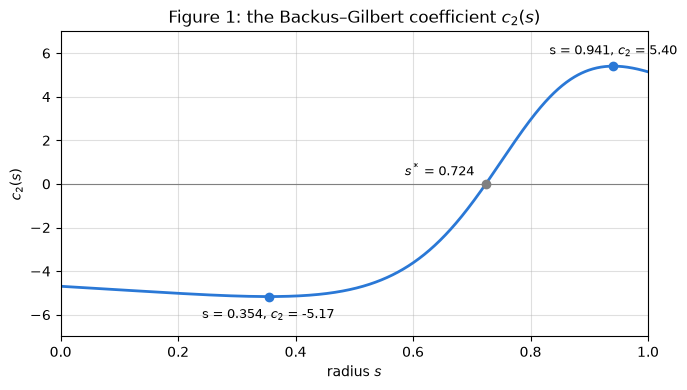

In [8]:
# Figure 1: the Backus-Gilbert coefficient c2(s)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(s_vals, c2_vals, color='#2a78d6', lw=2)
ax.axhline(0, color='grey', lw=0.8)
for i in (i_min, i_max):
    ax.plot(s_vals[i], c2_vals[i], 'o', color='#2a78d6')
    ax.annotate(f's = {s_vals[i]:.3f}, $c_2$ = {c2_vals[i]:.2f}', (s_vals[i], c2_vals[i]),
                textcoords='offset points', xytext=(0, -16 if i == i_min else 8), ha='center', fontsize=9)
ax.plot(float(s_star), 0, 'o', color='grey')
ax.annotate(f'$s^*$ = {float(s_star):.3f}', (float(s_star), 0), textcoords='offset points',
            xytext=(-8, 6), ha='right', fontsize=9)
ax.set_xlim(0, 1); ax.set_ylim(-7, 7)
ax.set_xlabel('radius $s$'); ax.set_ylabel('$c_2(s)$')
ax.set_title('Figure 1: the Backus–Gilbert coefficient $c_2(s)$')
ax.grid(alpha=0.4)
plt.tight_layout(); plt.show()

### 2.7.1 Radius of gyration

Writing the radius of gyration as a fraction $k$ of the disc radius,

$$k^2 = \frac{I}{MR^2} = \frac{\int x^2\,dm}{\int dm} = \frac{\mu_2}{\mu_1} \quad (28).$$

For a uniform disc $k_0^2 = \tfrac12$, and substituting into (25) gives $\delta = \mu_1\big(k^2 - k_0^2\big)$ (29). Writing the mass as a sum over rings,

$$\delta = \int_0^1 \tilde\rho(x)\,w(x)\,dx, \qquad w(x) = x\big(x^2 - k_0^2\big) = x^3 - \tfrac12 x \quad (30).$$

The weight function $w(x)$ is zero at $x = 0$ and at $x = k_0 = 1/\sqrt2 \approx 0.707$, negative in between with a minimum of $-0.136$ at $x = 1/\sqrt6$, and positive outside, reaching $0.5$ at the rim.

**Property 3 (Blind regions).** Density changes near $x = 0$ and near $x = 1/\sqrt2$, where $w \approx 0$, alter the mass but leave $\delta$ almost unchanged. Near the rim, $w$ is about 3.7 times larger than anywhere inside $x = 1/\sqrt2$.

**Property 4 (Location sets the sign).** The sign of $\delta$ is set by which side of $x = 1/\sqrt2$ the change occurs and whether mass is added or removed.

The cell below checks (29) and (30) and the values of $w$ quoted above, then draws Figure 2. The grey bands mark where $|w(x)| < 0.05$.

In [9]:
k0_sq = Rational(1, 2)
w = x*(x**2 - k0_sq)                                       # weight function (30)

# check (29) and (30) on a test density
rho = lambda xi: 1 + 0.2*xi
mu1, mu2 = moments(rho)
rho_bar, delta = mean_density_and_lean(mu1, mu2)
k2 = mu2/mu1                                               # (28)
print(f'delta = {delta:.6f};  mu1 (k^2 - k0^2) = {mu1*(k2 - 0.5):.6f}  (29);  '
      f'integral of rho w = {quad(lambda xi: rho(xi)*float(w.subs(x, xi)), 0, 1)[0]:.6f}  (30)')

# values of w quoted in Section 2.7.1 and Property 3
x_min = 1/sqrt(6)
w_min, w_rim = float(w.subs(x, x_min)), float(w.subs(x, 1))
print('w = 0 at x =', [root for root in solve(w, x) if root >= 0])
print(f'minimum w = {w_min:.3f} at x = 1/sqrt(6) = {float(x_min):.3f};  w(1) = {w_rim};  ratio = {w_rim/abs(w_min):.2f}')

delta = 0.006667;  mu1 (k^2 - k0^2) = 0.006667  (29);  integral of rho w = 0.006667  (30)
w = 0 at x = [0, sqrt(2)/2]
minimum w = -0.136 at x = 1/sqrt(6) = 0.408;  w(1) = 0.5;  ratio = 3.67


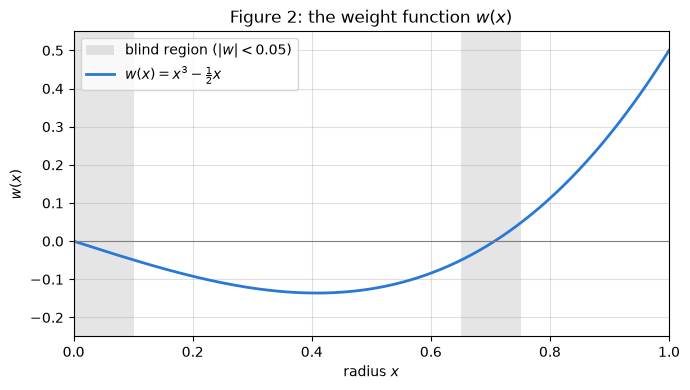

In [10]:
# Figure 2: the weight function w(x), with the blind regions shaded grey
BLIND = 0.05                                               # |w| below this counts as blind
w_vals = lambdify(x, w, 'numpy')(s_vals)
fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(s_vals, -0.25, 0.55, where=np.abs(w_vals) < BLIND, color='grey', alpha=0.2, lw=0,
                label=f'blind region ($|w| < {BLIND}$)')
ax.plot(s_vals, w_vals, color='#2a78d6', lw=2, label='$w(x) = x^3 - \\frac{1}{2}x$')
ax.axhline(0, color='grey', lw=0.8)
ax.set_xlim(0, 1); ax.set_ylim(-0.25, 0.55)
ax.set_xlabel('radius $x$'); ax.set_ylabel('$w(x)$')
ax.set_title('Figure 2: the weight function $w(x)$')
ax.legend(loc='upper left'); ax.grid(alpha=0.4)
plt.tight_layout(); plt.show()

## 3 Testing approach

To test these properties, we apply the estimate to densities whose true profiles are known, score how close each estimate is to the truth, and then repeat the tests with realistic measurement noise.

### 3.1 Test densities

We use 15 test densities in two groups (Table 1). **Smooth densities** change gradually across the disc; apart from the uniform control, each has a range of 0.2, which is why the oscillating density has an amplitude of 0.1. **Defects** are sudden changes: a uniform disc ($\rho = 1$) with either a region that is 20% lighter or heavier, or a ring of width 0.1 that is 50% lighter.

| Group | Density | $\rho(r)$ |
| --- | --- | --- |
| Smooth | Uniform (control) | $1$ |
| | Outward, linear | $1 + 0.2r$ |
| | Outward, quadratic | $1 + 0.2r^2$ |
| | Outward, cubic | $1 + 0.2r^3$ |
| | Inward, linear | $1 - 0.2r$ |
| | Inward, quadratic | $1.2 - 0.2r^2$ |
| | Bump | $1 + 0.2\sin(\pi r)$ |
| | Oscillating | $1 + 0.1\cos(4\pi r)$ |
| Defects | Porous rim | $0.8$ for $r > 0.7$ |
| | Porous core | $0.8$ for $r < 0.3$ |
| | Dense inner region | $1.2$ for $r < 0.5$ |
| | Void ring | $0.5$ for $0.20 \le r \le 0.30$ |
| | Void ring | $0.5$ for $0.45 \le r \le 0.55$ |
| | Void ring | $0.5$ for $0.65 \le r \le 0.75$ |
| | Void ring | $0.5$ for $0.80 \le r \le 0.90$ |

Each defect density equals 1 outside the stated region. Each entry below is `name: (density, radii where it jumps)`; for each density, $\mu_1$ and $\mu_2$ are computed by numerical integration of (3) and (4), split at those radii.

In [11]:
def void_ring(a, b):
    # uniform disc with density 0.5 for a <= r <= b
    return lambda xi: 0.5 if a <= xi <= b else 1.0


smooth_tests = {                                           # Table 1, smooth
    'Uniform (control)':                   (lambda xi: 1.0,                         None),
    'Outward, linear: 1 + 0.2r':           (lambda xi: 1 + 0.2*xi,                  None),
    'Outward, quadratic: 1 + 0.2r^2':      (lambda xi: 1 + 0.2*xi**2,               None),
    'Outward, cubic: 1 + 0.2r^3':          (lambda xi: 1 + 0.2*xi**3,               None),
    'Inward, linear: 1 - 0.2r':            (lambda xi: 1 - 0.2*xi,                  None),
    'Inward, quadratic: 1.2 - 0.2r^2':     (lambda xi: 1.2 - 0.2*xi**2,             None),
    'Bump: 1 + 0.2 sin(pi r)':             (lambda xi: 1 + 0.2*np.sin(np.pi*xi),    None),
    'Oscillating: 1 + 0.1 cos(4 pi r)':    (lambda xi: 1 + 0.1*np.cos(4*np.pi*xi),  None),
}
defect_tests = {                                           # Table 1, defects
    'Porous rim: 0.8 for r > 0.7':         (lambda xi: 0.8 if xi > 0.7 else 1.0,    [0.7]),
    'Porous core: 0.8 for r < 0.3':        (lambda xi: 0.8 if xi < 0.3 else 1.0,    [0.3]),
    'Dense inner region: 1.2 for r < 0.5': (lambda xi: 1.2 if xi < 0.5 else 1.0,    [0.5]),
    'Void ring 0.20-0.30':                 (void_ring(0.20, 0.30),                  [0.20, 0.30]),
    'Void ring 0.45-0.55':                 (void_ring(0.45, 0.55),                  [0.45, 0.55]),
    'Void ring 0.65-0.75':                 (void_ring(0.65, 0.75),                  [0.65, 0.75]),
    'Void ring 0.80-0.90':                 (void_ring(0.80, 0.90),                  [0.80, 0.90]),
}
all_tests = {**smooth_tests, **defect_tests}

### 3.2 Scoring metric

Each estimate is evaluated on the grid of radii $s_1, \dots, s_n$ with $n = 1001$. At each grid point, $\rho_i$ is the true density and $\hat\rho_i$ the estimate, and angle brackets denote the average over the grid:

$$\langle\rho\rangle = \frac1n\sum_{i=1}^n \rho_i, \qquad \langle\hat\rho\rangle = \frac1n\sum_{i=1}^n \hat\rho_i, \qquad \text{Var}(\rho) = \frac1n\sum_{i=1}^n \big(\rho_i - \langle\rho\rangle\big)^2 \quad (32).$$

Each curve's own average is subtracted before comparing them, and the result is scored with the Nash–Sutcliffe efficiency:

$$R^2_{\text{shape}} = 1 - \frac{\frac1n\sum_i \big[(\hat\rho_i - \langle\hat\rho\rangle) - (\rho_i - \langle\rho\rangle)\big]^2}{\text{Var}(\rho)} \quad (33).$$

$R^2_{\text{shape}} = 1$ is a perfect shape and $0$ is no better than a flat line. The uniform control has $\text{Var}(\rho) = 0$, so it is not scored.

The tables below give, for each density, $\bar\rho$ and $\delta$ (25), $R^2_{\text{shape}}$ (33, Table 6), and where the estimate is lowest (Property 1). Figures 5 and 6 show the true densities and their estimates.

In [12]:
def r2_shape(rho_i, rho_hat_i):
    # shape-only R^2 (33), using the grid averages and variance (32)
    var = np.mean((rho_i - rho_i.mean())**2)
    if var == 0:
        return np.nan                                      # uniform control: not scored
    return 1 - np.mean(((rho_hat_i - rho_hat_i.mean()) - (rho_i - rho_i.mean()))**2) / var


def score(tests):
    rows, curves = [], {}
    for name, (rho, jumps) in tests.items():
        rho_i = np.array([rho(xi) for xi in s_vals])
        rho_hat_i, mu1, mu2 = estimate(rho, jumps)
        rho_bar, delta = mean_density_and_lean(mu1, mu2)
        curves[name] = (rho_i, rho_hat_i)
        rows.append({'density': name, 'rho_bar': rho_bar, 'delta': delta,
                     'R2_shape': r2_shape(rho_i, rho_hat_i),
                     # Property 1; a flat estimate (delta = 0) has no lowest point
                     'estimate lowest at s': s_vals[np.argmin(rho_hat_i)] if abs(delta) > 1e-12 else np.nan})
    return pd.DataFrame(rows).set_index('density'), curves


def plot_estimates(curves, title, ncols=4):
    names = list(curves)
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4*ncols, 3.2*nrows), sharex=True)
    axes = list(np.atleast_1d(axes).flat)
    for ax, name in zip(axes, names):
        rho_i, rho_hat_i = curves[name]
        ax.plot(s_vals, rho_i, color='#1f1f1f', label='true density $\\rho$')
        ax.plot(s_vals, rho_hat_i, color='#2a78d6', label='estimate $\\hat\\rho$')
        ax.set_title(name, fontsize=10)
        ax.grid(alpha=0.4)
    for ax in axes[len(names):]:
        ax.set_visible(False)
    axes[0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout(); plt.show()

In [13]:
smooth_results, smooth_curves = score(smooth_tests)
smooth_results.round(3)

,rho_bar,delta,R2_shape,estimate lowest at s
density,,,,
Uniform (control),1.000,0.000,NaN,NaN
"Outward, linear: 1 + 0.2r",1.133,0.007,0.580,0.354
"Outward, quadratic: 1 + 0.2r^2",1.100,0.008,0.746,0.354
"Outward, cubic: 1 + 0.2r^3",1.080,0.009,0.805,0.354
"Inward, linear: 1 - 0.2r",0.867,-0.007,0.580,0.941
"Inward, quadratic: 1.2 - 0.2r^2",1.100,-0.008,0.746,0.941
Bump: 1 + 0.2 sin(pi r),1.127,-0.007,0.221,0.941
Oscillating: 1 + 0.1 cos(4 pi r),1.000,0.002,-0.015,0.354


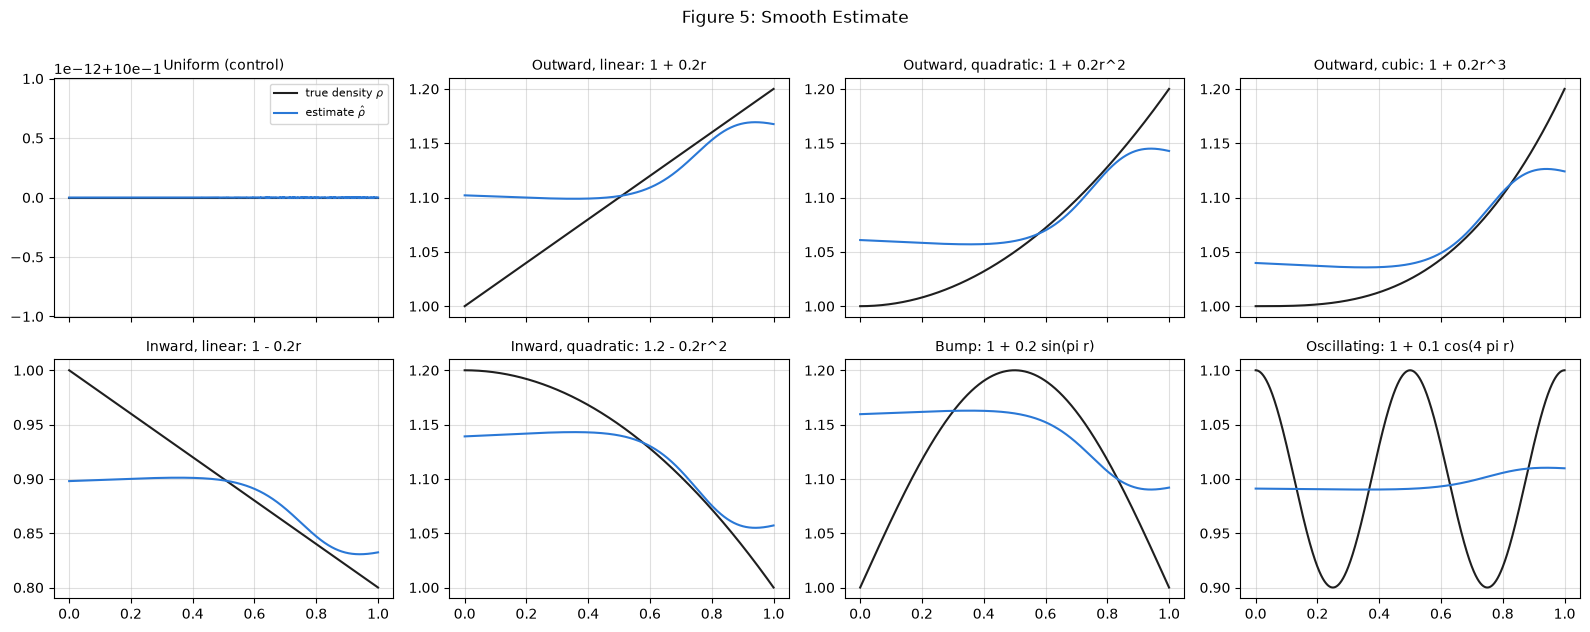

In [14]:
plot_estimates(smooth_curves, 'Figure 5: Smooth Estimate')

In [15]:
defect_results, defect_curves = score(defect_tests)
defect_results.round(3)

,rho_bar,delta,R2_shape,estimate lowest at s
density,,,,
Porous rim: 0.8 for r > 0.7,0.898,-0.012,0.721,0.941
Porous core: 0.8 for r < 0.3,0.982,0.004,0.135,0.354
Dense inner region: 1.2 for r < 0.5,1.050,-0.009,0.405,0.941
Void ring 0.20-0.30,0.975,0.005,0.052,0.354
Void ring 0.45-0.55,0.950,0.006,0.047,0.354
Void ring 0.65-0.75,0.930,0.000,-0.002,0.354
Void ring 0.80-0.90,0.915,-0.010,0.210,0.941


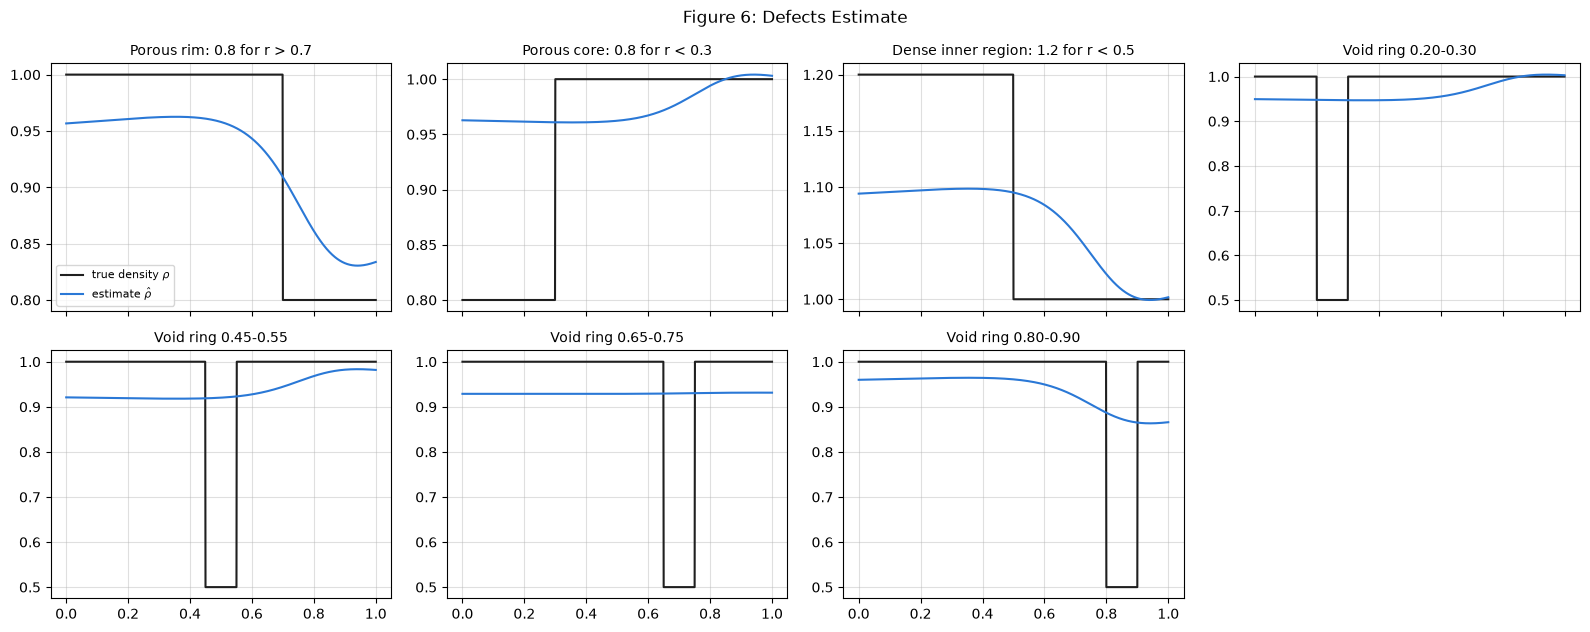

In [16]:
plot_estimates(defect_curves, 'Figure 6: Defects Estimate')

### 3.3 Measurement error

Each measurement is modelled as its true value with a small random relative error,

$$\mu_1^{\text{meas}} = \mu_1(1 + \varepsilon_M), \qquad \mu_2^{\text{meas}} = \mu_2(1 + \varepsilon_I), \qquad \varepsilon_M \sim N(0, \sigma_M^2), \quad \varepsilon_I \sim N(0, \sigma_I^2) \quad (34).$$

The two errors are independent, since the mass and the moment of inertia are measured with different instruments. The coefficients $c_1(s)$ and $c_2(s)$ come from the theory, so they carry no error. The mass error is fixed at $\sigma_M = 0.01\%$, and $\sigma_I$ is varied across four instruments (Table 3). The trifilar pendulum ($\sigma_I = 1\%$) is the main case.

| Measurement | Instrument | Error used |
| --- | --- | --- |
| Mass, $\sigma_M$ | Laboratory balance | 0.01% [17, 18] |
| Moment of inertia, $\sigma_I$ | Commercial instrument | 0.1% [19] |
| | Metrology torsion pendulum | 0.2% [20] |
| | Trifilar pendulum (main case) | 1% [20, 21] |
| | Poorly controlled set-up | 4.5% [22] |

The standard deviation of the estimate at radius $s$ is

$$\sigma_{\hat\rho}(s) = \sqrt{\big(c_1(s)\,\mu_1\sigma_M\big)^2 + \big(c_2(s)\,\mu_2\sigma_I\big)^2} \quad (35),$$

so $\hat\rho(s) \pm 1.96\,\sigma_{\hat\rho}(s)$ contains the error-free estimate 95% of the time at each $s$. The same reasoning applied to (25) gives

$$\sigma_{\bar\rho} = 2\mu_1\sigma_M, \qquad \sigma_\delta = \sqrt{(\mu_2\sigma_I)^2 + \big(\tfrac12\mu_1\sigma_M\big)^2} \quad (36),$$

and the signal-to-noise ratio is

$$\text{SNR} = \frac{|\delta|}{\sigma_\delta} \quad (37).$$

The estimate points the right way, that is, the measured $\delta$ has the sign of the true $\delta$, with probability $\Phi(\text{SNR})$, where $\Phi$ is the standard normal distribution function.

References (numbered as in the report): [17] Davidson, Potgieter and Gabelaia, *Good Practice Guide: Mass and Weight Measurement*, NPL, 2026. [18] United States Pharmacopeia, *FAQs: ⟨41⟩ Balances and ⟨1251⟩ Weighing on an Analytical Balance*. [19] Raptor Scientific, *MOI Measurement Instruments Overview*, 2024. [20] Pisani et al., "A device for measuring the moment of inertia for aerospace applications", IEEE MetroAeroSpace, 2019. [21] du Bois, Lieven and Adhikari, "Error analysis in trifilar inertia measurements", *Experimental Mechanics* 49, 2009. [22] Klaus, "Comparison of two experiments based on a physical and a torsion pendulum...", *Measurement Science Review* 17(1), 2017.

In [17]:
sigma_M = 1e-4                                             # mass, laboratory balance: 0.01%
instruments = {                                            # moment of inertia, Table 3
    'Commercial instrument':          0.001,
    'Metrology torsion pendulum':     0.002,
    'Trifilar pendulum (main case)':  0.01,
    'Poorly controlled set-up':       0.045,
}
MAIN_CASE = 'Trifilar pendulum (main case)'
rng = np.random.default_rng(2026)                          # fixed seed: every run gives identical numbers
N_TRIALS = 2000


def sigma_rho_hat(mu1, mu2, sigma_I):
    return np.sqrt((c1_vals*mu1*sigma_M)**2 + (c2_vals*mu2*sigma_I)**2)     # (35)


def sigma_rho_bar(mu1):
    return 2*mu1*sigma_M                                                    # (36)


def sigma_delta(mu1, mu2, sigma_I):
    return np.sqrt((mu2*sigma_I)**2 + (0.5*mu1*sigma_M)**2)                 # (36)


def measure(mu1, mu2, sigma_I, n=N_TRIALS):
    # n repeated measurements of mu1 and mu2 with independent relative errors, (34)
    return (mu1*(1 + sigma_M*rng.standard_normal(n)),
            mu2*(1 + sigma_I*rng.standard_normal(n)))

The cell below evaluates (36) and (37) for the cases quoted in Section 3.3: a uniform disc and $1 + 0.2x$, both measured with the trifilar pendulum.

In [18]:
sI = instruments[MAIN_CASE]
for label, rho in [('uniform disc', lambda xi: 1.0), ('1 + 0.2x', lambda xi: 1 + 0.2*xi)]:
    mu1, mu2 = moments(rho)
    rho_bar, delta = mean_density_and_lean(mu1, mu2)
    sd = sigma_delta(mu1, mu2, sI)
    line = f'{label:13s} sigma_rho_bar = {sigma_rho_bar(mu1):.6f}   sigma_delta = {sd:.6f}   delta = {delta:.6f}'
    if delta != 0:
        line += f'   SNR = {abs(delta)/sd:.2f}   Phi(SNR) = {100*norm.cdf(abs(delta)/sd):.1f}%'
    print(line)

uniform disc  sigma_rho_bar = 0.000100   sigma_delta = 0.002500   delta = 0.000000
1 + 0.2x      sigma_rho_bar = 0.000113   sigma_delta = 0.002900   delta = 0.006667   SNR = 2.30   Phi(SNR) = 98.9%


We check (35) and $\Phi(\text{SNR})$ against a Monte Carlo simulation of 2000 repeated measurements (34) for every test density and instrument. For each one the table records:

- the largest relative difference between the simulated standard deviation of $\hat\rho(s)$ and (35), over the grid;
- the share of simulated estimates inside $\pm 1.96\,\sigma_{\hat\rho}(s)$ of the error-free estimate, averaged over the grid;
- $\Phi(\text{SNR})$ and the simulated share of measurements whose $\delta$ has the sign of the true $\delta$ (not defined for the uniform control, whose true $\delta$ is zero);
- the range containing the middle 90% of $R^2_{\text{shape}}$ (33) over the simulated measurements, from its 5th to its 95th percentile (not defined for the uniform control).

The table shows the main case; `mc_check` holds all four instruments.

In [19]:
def r2_shape_per_measurement(rho_i, rho_hat_meas):
    # shape-only R^2 (33) of every simulated estimate (one per row)
    var = np.mean((rho_i - rho_i.mean())**2)
    if var == 0:
        return np.full(len(rho_hat_meas), np.nan)          # uniform control: not scored
    dev = rho_hat_meas - rho_hat_meas.mean(axis=1, keepdims=True)
    return 1 - np.mean((dev - (rho_i - rho_i.mean()))**2, axis=1) / var


mc_rows = []
for name, (rho, jumps) in all_tests.items():
    rho_i = np.array([rho(xi) for xi in s_vals])
    rho_hat_i, mu1, mu2 = estimate(rho, jumps)
    rho_bar, delta = mean_density_and_lean(mu1, mu2)
    for instrument, sI in instruments.items():
        mu1_meas, mu2_meas = measure(mu1, mu2, sI)
        rho_hat_meas = np.outer(mu1_meas, c1_vals) + np.outer(mu2_meas, c2_vals)   # one estimate (5) per row
        delta_meas = mu2_meas - mu1_meas/2
        sd_exact = sigma_rho_hat(mu1, mu2, sI)
        sd_delta = sigma_delta(mu1, mu2, sI)
        inside = np.abs(rho_hat_meas - rho_hat_i) <= 1.96*sd_exact
        r2 = r2_shape_per_measurement(rho_i, rho_hat_meas)
        mc_rows.append({
            'density': name, 'instrument': instrument, 'delta': delta, 'sigma_delta': sd_delta,
            'SNR': abs(delta)/sd_delta,
            'max |MC - (35)| / (35) (%)': 100*np.max(np.abs(rho_hat_meas.std(axis=0) - sd_exact)/sd_exact),
            'inside +-1.96 sigma (%)': 100*inside.mean(),
            'Phi(SNR) (%)': np.nan if delta == 0 else 100*norm.cdf(abs(delta)/sd_delta),
            'simulated correct sign (%)': np.nan if delta == 0 else 100*np.mean(np.sign(delta_meas) == np.sign(delta)),
            'R2_shape 5%': np.nan if np.isnan(r2).all() else np.percentile(r2, 5),
            'R2_shape 95%': np.nan if np.isnan(r2).all() else np.percentile(r2, 95),
        })
mc_check = pd.DataFrame(mc_rows)

(mc_check[mc_check.instrument == MAIN_CASE].drop(columns='instrument').set_index('density')
 .round({'delta': 4, 'sigma_delta': 4, 'SNR': 2, 'max |MC - (35)| / (35) (%)': 1,
         'inside +-1.96 sigma (%)': 1, 'Phi(SNR) (%)': 1, 'simulated correct sign (%)': 1,
         'R2_shape 5%': 2, 'R2_shape 95%': 2}))

,delta,sigma_delta,SNR,max |MC - (35)| / (35) (%),inside +-1.96 sigma (%),Phi(SNR) (%),simulated correct sign (%),R2_shape 5%,R2_shape 95%
density,,,,,,,,,
Uniform (control),0.0000,0.0025,0.00,1.7,95.1,NaN,NaN,NaN,NaN
"Outward, linear: 1 + 0.2r",0.0067,0.0029,2.30,2.4,94.6,98.9,99.2,0.20,0.74
"Outward, quadratic: 1 + 0.2r^2",0.0083,0.0028,2.94,3.5,95.3,99.8,99.8,0.40,0.90
"Outward, cubic: 1 + 0.2r^3",0.0086,0.0028,3.08,1.9,94.7,99.9,100.0,0.47,0.94
"Inward, linear: 1 - 0.2r",-0.0067,0.0021,3.17,0.9,95.0,99.9,99.9,0.34,0.72
"Inward, quadratic: 1.2 - 0.2r^2",-0.0083,0.0027,3.12,5.3,95.8,99.9,99.9,0.43,0.89
Bump: 1 + 0.2 sin(pi r),-0.0069,0.0027,2.50,2.2,95.3,99.4,99.1,0.10,0.22
Oscillating: 1 + 0.1 cos(4 pi r),0.0019,0.0025,0.75,1.5,95.0,77.5,78.8,-0.13,0.00
Porous rim: 0.8 for r > 0.7,-0.0125,0.0021,5.89,3.4,95.1,100.0,100.0,0.58,0.82


Figure 3 shows the distribution of the measured $\delta$ for $1 + 0.2x$ with the trifilar pendulum. The curve is the model $N(\delta, \sigma_\delta^2)$, the outline is a histogram of 2000 simulated measurements, and the blue area, the probability that the measured $\delta$ has the correct sign, is $\Phi(\text{SNR})$.

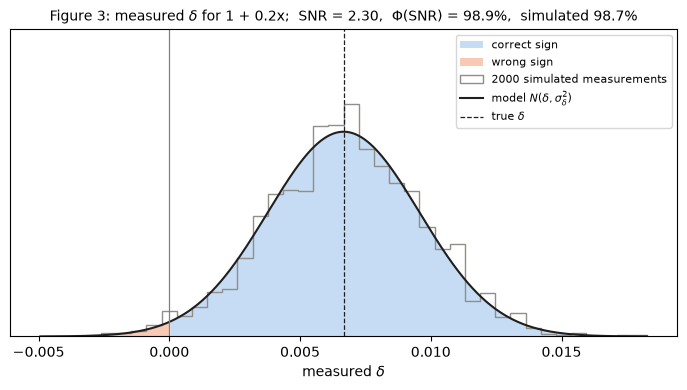

In [20]:
# Figure 3: distribution of the measured delta for 1 + 0.2x, trifilar pendulum
rho = lambda xi: 1 + 0.2*xi
mu1, mu2 = moments(rho)
rho_bar, delta = mean_density_and_lean(mu1, mu2)
sd = sigma_delta(mu1, mu2, instruments[MAIN_CASE])
mu1_meas, mu2_meas = measure(mu1, mu2, instruments[MAIN_CASE])
delta_meas = mu2_meas - mu1_meas/2

d = np.linspace(delta - 4*sd, delta + 4*sd, 801)
pdf = norm.pdf(d, delta, sd)
fig, ax = plt.subplots(figsize=(7, 4))
ax.fill_between(d, pdf, where=d > 0, color='#c6dcf5', lw=0, label='correct sign')
ax.fill_between(d, pdf, where=d <= 0, color='#f8c9b4', lw=0, label='wrong sign')
ax.hist(delta_meas, bins=40, range=(d[0], d[-1]), density=True, histtype='step', color='#8f8e89',
        label=f'{N_TRIALS} simulated measurements')
ax.plot(d, pdf, color='#1f1f1f', lw=1.5, label='model $N(\\delta, \\sigma_\\delta^2)$')
ax.axvline(0, color='grey', lw=0.9)
ax.axvline(delta, color='#1f1f1f', lw=0.9, ls='--', label='true $\\delta$')
ax.set_ylim(0, 1.5*pdf.max()); ax.set_yticks([]); ax.set_xlabel('measured $\\delta$')
ax.set_title(f'Figure 3: measured $\\delta$ for 1 + 0.2x;  SNR = {abs(delta)/sd:.2f},  '
             f'$\\Phi$(SNR) = {100*norm.cdf(abs(delta)/sd):.1f}%,  '
             f'simulated {100*np.mean(delta_meas > 0):.1f}%', fontsize=10)
ax.legend(fontsize=8, loc='upper right')
plt.tight_layout(); plt.show()

## 5 Results

The results table collects the numbers for every test density, first without measurement error and then with the trifilar pendulum ($\sigma_I = 1\%$):

- **No measurement error:** the outward-lean number $\delta$ (25), the radius at which the estimate is lowest (Property 1), and $R^2_{\text{shape}}$ (33).
- **Trifilar pendulum:** the SNR of $\delta$ (37), the probability $\Phi(\text{SNR})$ that the estimate points the right way, and the range containing the middle 90% of $R^2_{\text{shape}}$ over 2000 simulated measurements (its 5th to 95th percentile).

The uniform control is omitted because $\text{Var}(\rho) = 0$.

In [21]:
report_name = {                                            # row names as in the report's table
    'Outward, linear: 1 + 0.2r': '1 + 0.2r',       'Outward, quadratic: 1 + 0.2r^2': '1 + 0.2r^2',
    'Outward, cubic: 1 + 0.2r^3': '1 + 0.2r^3',    'Inward, linear: 1 - 0.2r': '1 - 0.2r',
    'Inward, quadratic: 1.2 - 0.2r^2': '1.2 - 0.2r^2', 'Bump: 1 + 0.2 sin(pi r)': '1 + 0.2 sin(pi r)',
    'Oscillating: 1 + 0.1 cos(4 pi r)': '1 + 0.1 cos(4 pi r)',
    'Porous rim: 0.8 for r > 0.7': 'Porous rim',    'Porous core: 0.8 for r < 0.3': 'Porous core',
    'Dense inner region: 1.2 for r < 0.5': 'Dense inner region',
    'Void ring 0.20-0.30': 'Void ring 0.20-0.30',   'Void ring 0.45-0.55': 'Void ring 0.45-0.55',
    'Void ring 0.65-0.75': 'Pivot void 0.65-0.75',  'Void ring 0.80-0.90': 'Void ring 0.80-0.90',
}
exact = pd.concat([smooth_results, defect_results])
main = mc_check[mc_check.instrument == MAIN_CASE].set_index('density')

rows = []
for name, label in report_name.items():
    e, m = exact.loc[name], main.loc[name]
    phi = m['Phi(SNR) (%)']
    rows.append({
        ('', 'Density'): label,
        ('No measurement error', 'delta'): f"{m['delta']:.4f}",
        ('No measurement error', 'Lowest at s'): f"{e['estimate lowest at s']:.3f}",
        ('No measurement error', 'R2_shape'): f"{e['R2_shape']:.3f}",
        ('Trifilar pendulum, sigma_I = 1%', 'SNR'): f"{m['SNR']:.1f}",
        ('Trifilar pendulum, sigma_I = 1%', 'Phi(SNR)'): '100%' if round(phi, 1) == 100 else f'{phi:.1f}%',
        ('Trifilar pendulum, sigma_I = 1%', 'R2_shape, 5-95%'): f"{m['R2_shape 5%']:.2f} to {m['R2_shape 95%']:.2f}",
    })
results_table = pd.DataFrame(rows).set_index(('', 'Density'))
results_table.index.name = 'Density'
results_table.columns = pd.MultiIndex.from_tuples(results_table.columns)
results_table

No measurement error                       \
                                    delta Lowest at s R2_shape   
Density                                                          
1 + 0.2r                           0.0067       0.354    0.580   
1 + 0.2r^2                         0.0083       0.354    0.746   
1 + 0.2r^3                         0.0086       0.354    0.805   
1 - 0.2r                          -0.0067       0.941    0.580   
1.2 - 0.2r^2                      -0.0083       0.941    0.746   
1 + 0.2 sin(pi r)                 -0.0069       0.941    0.221   
1 + 0.1 cos(4 pi r)                0.0019       0.354   -0.015   
Porous rim                        -0.0125       0.941    0.721   
Porous core                        0.0041       0.354    0.135   
Dense inner region                -0.0094       0.941    0.405   
Void ring 0.20-0.30                0.0054       0.354    0.052   
Void ring 0.45-0.55                0.0062       0.354    0.047   
Pivot void 0.65-0.75               0.0003       0.354   -0.002   
Void ring 0.80-0.90               -0.0096       0.941    0.210   

                     Trifilar pendulum, sigma_I = 1%                           
                                                 SNR Phi(SNR) R2_shape, 5-95%  
Density                                                                        
1 + 0.2r                                         2.3    98.9%    0.20 to 0.74  
1 + 0.2r^2                                       2.9    99.8%    0.40 to 0.90  
1 + 0.2r^3                                       3.1    99.9%    0.47 to 0.94  
1 - 0.2r                                         3.2    99.9%    0.34 to 0.72  
1.2 - 0.2r^2                                     3.1    99.9%    0.43 to 0.89  
1 + 0.2 sin(pi r)                                2.5    99.4%    0.10 to 0.22  
1 + 0.1 cos(4 pi r)                              0.8    77.5%   -0.13 to 0.00  
Porous rim                                       5.9     100%    0.58 to 0.82  
Porous core                                      1.6    95.0%   -0.01 to 0.21  
Dense inner region                               3.7     100%    0.26 to 0.50  
Void ring 0.20-0.30                              2.2    98.5%    0.02 to 0.06  
Void ring 0.45-0.55                              2.5    99.4%    0.02 to 0.05  
Pivot void 0.65-0.75                             0.1    54.5%   -0.03 to 0.01  
Void ring 0.80-0.90                              4.4     100%    0.14 to 0.26